# Módulo 7 · Python con asistencia de IA, estadística y regresión

**Versión resuelta para docentes.**

En esta clase nadie escribe código desde cero: se **pide** al asistente, se **lee** lo que generó, se **ejecuta** y se **verifica**.

| Bloque | Producto |
|---|---|
| 1. Entorno | Los datos cargados de dos formas |
| 2. Estadística descriptiva | Tabla resumen de las variables |
| 3. Visualización | Una figura lista para publicar |
| 4. Regresión, sobreajuste y métricas | Ajuste lineal, ajuste de curvas y gráfico de error por grado del polinomio |
| Cierre | Elección justificada de un modelo |

**Cómo trabajar con este cuaderno**

- Cada bloque empieza con un **ejemplo resuelto**. Después vienen las **consignas**: dicen qué se espera, no cómo pedirlo. El prompt lo escribís vos.
- Si te trabás, abrí la pista **¿Te trabaste?** que hay debajo de cada consigna.
- Anotá el prompt que usaste en el espacio **Tu prompt**: sirve para revisar después qué funcionó.
- Las consignas de **verificación** piden comprobar un resultado antes de seguir. No las saltees.

## Sobre los datos

Trabajamos con **DNase**: la calibración de un ensayo ELISA para la proteína DNasa recombinante en suero de rata. Son 176 mediciones de densidad óptica, de 11 corridas del ensayo, con 8 concentraciones patrón medidas por duplicado en cada una.

**Cómo funciona un ELISA.** Es un inmunoensayo: un anticuerpo fijado al fondo de un pocillo captura la proteína que se quiere medir (el *analito*). En el formato más común, un segundo anticuerpo unido a una enzima se pega al analito capturado; al agregar un sustrato, la enzima produce un compuesto coloreado. Cuanto más analito hay, más color, y el color se mide como **densidad óptica** (una absorbancia) en un lector de placas. La documentación no detalla el formato exacto de este ensayo.

Para medir una muestra desconocida, primero se construye una **curva de calibración** con patrones de concentración conocida. Eso es lo que contiene este conjunto de datos.

**Cómo están organizados los datos.**

- **Corrida:** una ejecución completa del ensayo, en la que se vuelve a medir toda la serie de patrones. Las 11 corridas tienen **las mismas 8 concentraciones** (de 0,049 a 12,5), cada una medida **por duplicado**: 16 lecturas por corrida, 176 en total.
- Los números de corrida son **etiquetas**, no un orden cronológico. La documentación no dice qué cambió entre una corrida y otra (día, placa, operador o lote de reactivos).
- Hay dos fuentes de variabilidad: entre los duplicados de una misma corrida (**repetibilidad**) y entre corridas distintas (variabilidad **entre ensayos**).
- **Unidades:** la documentación no indica la unidad de concentración; por eso hablamos de "unidades del ensayo". La densidad óptica es adimensional.

**Más información.**

- **Documentación oficial del conjunto:** [DNase en la referencia de R](https://search.r-project.org/R/refmans/datasets/html/DNase.html)
- **Archivo CSV y su página:** [DNase en Rdatasets](https://vincentarelbundock.github.io/Rdatasets/doc/datasets/DNase.html)
- **Fuente original:** Davidian, M. y Giltinan, D. M. (1995). *Nonlinear Models for Repeated Measurement Data*. Chapman & Hall, sección 5.2.4.
- **Descripción detallada, licencia y datos simulados:** [`data/README.md`](../data/README.md) en la carpeta del curso.

## 0. Configuración

Esta es la **única celda** que nombra al conjunto de datos. El resto del cuaderno usa nombres genéricos (`datos`, `x`, `y`). Para trabajar con otros datos, se edita esta celda y se vuelve a ejecutar todo.

In [1]:
# === Configuración del conjunto de datos ===

# De dónde salen los datos (el mismo archivo en dos lugares)
RUTA_CSV = "../data/dnase.csv"  # copia del archivo en la carpeta del curso
URL_DATOS = "https://raw.githubusercontent.com/vincentarelbundock/Rdatasets/master/csv/datasets/DNase.csv"  # original publicado en internet
COLUMNAS_A_DESCARTAR = ["rownames"]  # columnas que no son datos
# Copia de los datos con lecturas anómalas simuladas (bloque 2).
RUTA_ANOMALIAS = "../data/dnase_con_anomalias.csv"

# Qué papel cumple cada columna
COLUMNA_X = "conc"        # variable de entrada: concentración conocida del patrón
COLUMNA_Y = "density"     # variable objetivo: densidad óptica medida
COLUMNA_GRUPO = "Run"     # variable categórica: corrida del ensayo

# Nombres para mostrar en tablas y gráficos
NOMBRE_X = "Concentración de DNasa (unidades del ensayo)"
NOMBRE_Y = "Densidad óptica"
NOMBRE_GRUPO = "Corrida"

# Bloque 2
UMBRAL_DUPLICADOS = 0.2  # diferencia máxima aceptable entre las dos lecturas duplicadas

# Bloque 4
GRUPO_CALIBRACION = 1   # corrida que se usa como curva de calibración
X_MAX_LINEAL = 1.6      # límite superior del tramo lineal de la calibración
DENSIDAD_MUESTRA = 0.30 # densidad óptica de una muestra de concentración desconocida
N_SIMULADOS = 18        # puntos del conjunto simulado para el sobreajuste
GRADO_MAXIMO = 10       # grado máximo del polinomio en el bloque de sobreajuste

SEMILLA = 32            # semilla fija: los resultados se repiten en cada ejecución

In [2]:
# Librerías que usa el cuaderno (con sus versiones en requirements.txt)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import curve_fit
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

sns.set_theme(style="whitegrid")

## Bloque 1 · Entorno: VS Code, OpenCode y carga de datos (25 min)

**Producto:** los datos cargados de dos formas y un error depurado.

Abrí la carpeta del curso en VS Code, abrí este cuaderno y elegí como *kernel* el entorno de Python del curso. El asistente de IA es OpenCode: a él le vas a pedir el código de cada consigna.

**Ejemplo resuelto.** Carga del archivo CSV que está en la carpeta `data` del curso. Ejecutá la celda y pedile al asistente que te explique, línea por línea, qué hace.

In [3]:
# Carga desde un archivo CSV de la carpeta del curso
datos = pd.read_csv(RUTA_CSV).drop(columns=COLUMNAS_A_DESCARTAR)
print("Filas y columnas:", datos.shape)
datos.head()

Filas y columnas: (176, 3)


,Run,conc,density
0,1,0.048828,0.017
1,1,0.048828,0.018
2,1,0.195312,0.121
3,1,0.195312,0.124
4,1,0.390625,0.206


#### Consigna 1.1 · Carga desde una URL

El mismo archivo está publicado en internet, en la dirección `URL_DATOS`. Cargalo en un DataFrame nuevo.

**Se espera:** una tabla con las mismas filas y columnas que `datos`, sin la columna `rownames`.

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

pandas puede leer un CSV directamente desde una dirección web, con la misma función del ejemplo. Fijate qué hace el ejemplo con `COLUMNAS_A_DESCARTAR`.

</details>

> **Prompt de referencia (docente)**
>
> Cargá en un DataFrame llamado `datos_url` el CSV de la dirección `URL_DATOS`, eliminá las columnas de `COLUMNAS_A_DESCARTAR` y mostrá cuántas filas y columnas tiene.

In [4]:
# Carga desde una dirección de internet
datos_url = pd.read_csv(URL_DATOS).drop(columns=COLUMNAS_A_DESCARTAR)
print("Filas y columnas:", datos_url.shape)

Filas y columnas: (176, 3)


#### Consigna 1.2 · Verificación: ¿son la misma tabla?

Comprobá con código, no a ojo, que las dos cargas dieron exactamente la misma tabla.

**Se espera:** un resultado `True` o `False`.

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

Que tengan la misma cantidad de filas no alcanza: pueden diferir los valores. pandas tiene una forma de comparar dos tablas completas de una vez.

</details>

> **Prompt de referencia (docente)**
>
> Comprobá si `datos` y `datos_url` son exactamente iguales e imprimí el resultado.

In [5]:
print("Archivo local y URL iguales:", datos.equals(datos_url))

Archivo local y URL iguales: True


#### Consigna 1.3 · Cuando algo falla: depurar sin saber programar

Tarde o temprano, una celda va a fallar. No hace falta saber programar para resolverlo, pero sí leer el mensaje de error y saber qué preguntarle al asistente. La celda siguiente falla: ejecutala y, antes de pedir ayuda, mirá la última línea del mensaje.

Después pedile al asistente que te explique **qué salió mal**, **por qué** y **cómo corregirlo**, y aplicá la corrección.

**Se espera:** una celda corregida que imprima la densidad óptica media, y una frase tuya que explique el error con tus palabras.

**Antes de seguir:** ¿la corrección del asistente usa las variables de la configuración o escribe el nombre de la columna a mano? ¿Por qué importa?

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

La última línea de un error de Python dice el tipo de error y qué lo causó. Copiá el mensaje completo en el chat del asistente: es la mejor información que le podés dar.

</details>

In [6]:
# Esta celda falla a propósito: leé el mensaje de error
print(datos["densidad"].mean())

KeyError: 'densidad'

> **Prompt de referencia (docente)**
>
> Explicá el error de esta celda en dos frases y proponé la corrección usando las variables de la configuración.

In [7]:
# Corrección: usar el nombre de columna definido en la configuración
print(datos[COLUMNA_Y].mean())

0.7191590909090909


## Bloque 2 · Estadística descriptiva (25 min)

**Producto:** tabla resumen de las variables.

**Ejemplo resuelto.** Tabla resumen de la variable de entrada y la variable objetivo.

In [8]:
tabla_resumen = datos[[COLUMNA_X, COLUMNA_Y]].agg(["count", "mean", "median", "std", "min", "max"]).T
tabla_resumen.columns = ["n", "media", "mediana", "desvío", "mínimo", "máximo"]
tabla_resumen.index = [NOMBRE_X, NOMBRE_Y]
tabla_resumen.round(3)

,n,media,mediana,desvío,mínimo,máximo
Concentración de DNasa (unidades del ensayo),176.0,3.107,1.172,4.060,0.049,12.500
Densidad óptica,176.0,0.719,0.526,0.596,0.011,2.003


#### Consigna 2.1 · Conteos y proporciones

Contá cuántas lecturas hay en cada corrida y qué proporción del total representa cada una.

**Se espera:** una tabla con 11 filas, una por corrida, y dos columnas: cantidad de lecturas y proporción. Las proporciones tienen que sumar 1.


<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

Primero contá cuántas lecturas tiene cada corrida; la proporción es ese conteo dividido por el total de lecturas (176).

</details>

> **Prompt de referencia (docente)**
>
> Contá cuántas mediciones hay en cada categoría de `COLUMNA_GRUPO` y qué proporción del total representa cada una. Mostralo en una tabla ordenada por categoría.

In [9]:
conteos = datos[COLUMNA_GRUPO].value_counts().sort_index()
tabla_grupos = pd.DataFrame({"mediciones": conteos, "proporción": (conteos / conteos.sum()).round(3)})
tabla_grupos.index.name = NOMBRE_GRUPO
tabla_grupos

,mediciones,proporción
Corrida,,
1,16,0.091
2,16,0.091
3,16,0.091
4,16,0.091
5,16,0.091
6,16,0.091
7,16,0.091
8,16,0.091
9,16,0.091


### Lecturas anómalas

En un laboratorio real, entre cientos de lecturas suele colarse alguna equivocada: un número mal tipeado, un pocillo contaminado, uno al que le faltó reactivo. Antes de analizar, hay que encontrarlas.

> ⚠️ **Datos con anomalías simuladas.** El archivo siguiente es una copia de los mismos datos en la que el equipo docente **alteró algunas lecturas** a propósito. No sabés cuántas ni cuáles: tu trabajo es encontrarlas.

> **Una regla de oro:** en ciencia no se borra un dato porque "se ve raro". Hace falta un **criterio** que se pueda explicar, y lo que se quita se **documenta**.

**Ejemplo resuelto.** Carga de los datos con anomalías.

In [10]:
datos_anomalos = pd.read_csv(RUTA_ANOMALIAS).drop(columns=COLUMNAS_A_DESCARTAR)
print("Filas y columnas:", datos_anomalos.shape)

Filas y columnas: (176, 3)


#### Consigna 2.2 · Diagnóstico visual

Mirá los datos con anomalías con dos gráficos: uno con todas las lecturas de densidad óptica juntas y otro con las lecturas de cada concentración patrón por separado (por ejemplo, un boxplot por concentración). Después listá las lecturas que te parezcan sospechosas.

**Se espera:** dos gráficos simples (el estilo no importa: eso es el bloque 3) y una tabla con las lecturas sospechosas, con su corrida, su concentración y su densidad óptica.

**Antes de seguir:** ¿Todas las lecturas sospechosas te parecen errores? Fijate de qué corridas son.

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

Un boxplot marca como puntos sueltos los valores que quedan lejos de la caja. Para listarlos con código, pedí la regla que usa el boxplot (1,5 veces el rango intercuartil) aplicada dentro de cada concentración. Si un solo valor aplasta la escala del gráfico, pedí limitar el eje y para ver el resto.

</details>

> **Prompt de referencia (docente)**
>
> Con `datos_anomalos`, hacé un histograma de `COLUMNA_Y` y un boxplot de `COLUMNA_Y` para cada valor de `COLUMNA_X`. Después listá en `sospechosas` las lecturas que quedan fuera de 1,5 rangos intercuartiles dentro de su concentración, con su corrida, concentración y valor.

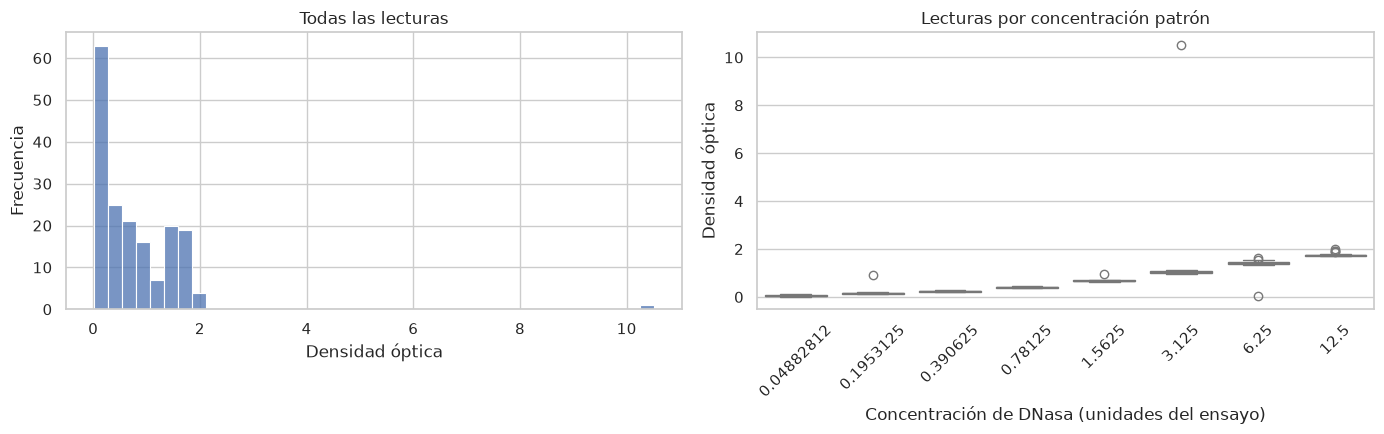

Lecturas sospechosas: 10


,Run,conc,density
50,4,0.195312,0.900
73,5,1.562500,0.950
106,7,3.125000,10.520
28,2,6.250000,1.554
44,3,6.250000,1.629
141,9,6.250000,0.030
30,2,12.500000,1.932
31,2,12.500000,1.914
46,3,12.500000,2.003
47,3,12.500000,1.884


In [11]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(data=datos_anomalos, x=COLUMNA_Y, bins=40, ax=ejes[0])
ejes[0].set(title="Todas las lecturas", xlabel=NOMBRE_Y, ylabel="Frecuencia")
sns.boxplot(data=datos_anomalos, x=COLUMNA_X, y=COLUMNA_Y, ax=ejes[1], color="lightsteelblue")
ejes[1].set(title="Lecturas por concentración patrón", xlabel=NOMBRE_X, ylabel=NOMBRE_Y)
ejes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

# Regla del boxplot dentro de cada concentración: fuera de [Q1 - 1,5·RIC, Q3 + 1,5·RIC]
def fuera_de_la_caja(lecturas):
    q1, q3 = lecturas.quantile([0.25, 0.75])
    ric = q3 - q1
    return (lecturas < q1 - 1.5 * ric) | (lecturas > q3 + 1.5 * ric)

es_sospechosa = datos_anomalos.groupby(COLUMNA_X)[COLUMNA_Y].transform(fuera_de_la_caja)
sospechosas = datos_anomalos[es_sospechosa]
print(f"Lecturas sospechosas: {len(sospechosas)}")
sospechosas.sort_values([COLUMNA_X, COLUMNA_GRUPO])

#### Consigna 2.3 · Un criterio con sentido experimental

Cada lectura se hizo por duplicado: en una misma corrida, las dos lecturas de una concentración deberían coincidir casi exactamente. Para cada par de duplicados, calculá la diferencia entre sus dos lecturas y marcá los pares cuya diferencia supere `UMBRAL_DUPLICADOS`.

**Se espera:** una tabla con los pares sospechosos: corrida, concentración, las dos lecturas y su diferencia.

**Antes de seguir:** Compará con la lista de la consigna 2.2. ¿Qué lecturas sospechosas desaparecieron? ¿Por qué tiene sentido que desaparezcan?

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

Agrupá las lecturas por corrida y concentración: cada grupo tiene exactamente dos filas. La diferencia es el máximo menos el mínimo del grupo.

</details>

> **Prompt de referencia (docente)**
>
> Agrupá `datos_anomalos` por `COLUMNA_GRUPO` y `COLUMNA_X`, calculá el mínimo, el máximo y la diferencia entre las dos lecturas de cada par, y guardá en `pares_sospechosos` los pares con diferencia mayor que `UMBRAL_DUPLICADOS`.

In [12]:
pares = datos_anomalos.groupby([COLUMNA_GRUPO, COLUMNA_X])[COLUMNA_Y].agg(["min", "max"])
pares["diferencia"] = pares["max"] - pares["min"]
pares_sospechosos = pares[pares["diferencia"] > UMBRAL_DUPLICADOS]
print(f"Pares con diferencia mayor que {UMBRAL_DUPLICADOS}: {len(pares_sospechosos)}")
pares_sospechosos.round(3)

Pares con diferencia mayor que 0.2: 4


,,min,max,diferencia
Run,conc,,,
4,0.195312,0.108,0.900,0.792
5,1.562500,0.658,0.950,0.292
7,3.125000,1.035,10.520,9.485
9,6.250000,0.030,1.398,1.368


#### Consigna 2.4 · Depurar y verificar

En cada par sospechoso, una lectura es la buena y la otra la anómala. Decidí cuál quitar comparando las dos con lo que midieron las demás corridas en esa misma concentración, y armá un DataFrame nuevo sin las lecturas anómalas. No modifiques `datos_anomalos`: así queda registro de lo que había.

**Se espera:** un DataFrame depurado, una tabla con las lecturas eliminadas (corrida, concentración, valor) y la cantidad de filas antes y después.

**Antes de seguir:** Escribí en una frase el criterio que usaste, como lo pondrías en la sección de métodos de un trabajo.

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

Para cada concentración, la mediana de todas las corridas es una buena referencia. En cada par, la lectura anómala es la que queda más lejos de esa mediana.

</details>

> **Prompt de referencia (docente)**
>
> Para cada par de `pares_sospechosos`, eliminá de `datos_anomalos` la lectura que más se aleja de la mediana de `COLUMNA_Y` en su concentración. Guardá el resultado en `datos_depurados` y las filas eliminadas en `eliminadas`, y mostrá cuántas filas había antes y cuántas quedan.

In [13]:
mediana_por_concentracion = datos_anomalos.groupby(COLUMNA_X)[COLUMNA_Y].median()

filas_a_eliminar = []
for (grupo, concentracion) in pares_sospechosos.index:
    par = datos_anomalos[(datos_anomalos[COLUMNA_GRUPO] == grupo) & (datos_anomalos[COLUMNA_X] == concentracion)]
    distancia = (par[COLUMNA_Y] - mediana_por_concentracion[concentracion]).abs()
    filas_a_eliminar.append(distancia.idxmax())  # la lectura más alejada de la mediana

eliminadas = datos_anomalos.loc[filas_a_eliminar]
datos_depurados = datos_anomalos.drop(index=filas_a_eliminar)
print(f"Filas antes: {len(datos_anomalos)}   |   eliminadas: {len(eliminadas)}   |   después: {len(datos_depurados)}")
eliminadas

Filas antes: 176   |   eliminadas: 4   |   después: 172


,Run,conc,density
50,4,0.195312,0.90
73,5,1.562500,0.95
106,7,3.125000,10.52
141,9,6.250000,0.03


> **Verificación docente.** La celda siguiente compara lo eliminado con la clave de las anomalías (ver `herramientas/crear_datos_anomalos.py`): las lecturas depuradas tienen que coincidir exactamente con los datos originales sin esas filas.

In [14]:
clave = {(7, 3.125), (4, 0.1953125), (9, 6.25), (5, 1.5625)}  # (corrida, concentración) alteradas
encontradas = set(zip(eliminadas[COLUMNA_GRUPO], eliminadas[COLUMNA_X]))
print("Las eliminadas coinciden con la clave:", encontradas == clave)
print("Los datos depurados coinciden con los originales:", datos_depurados.equals(datos.drop(index=filas_a_eliminar)))

Las eliminadas coinciden con la clave: True
Los datos depurados coinciden con los originales: True


#### Interpretación

- Las 11 corridas tienen la misma cantidad de lecturas (16, el 9,1 % cada una): el diseño está balanceado.
- La concentración tiene media 3,11 y mediana 1,17. La media queda muy por encima porque los patrones siguen una dilución seriada: hay muchos valores bajos y pocos altos.
- **Lecturas anómalas:** el archivo de la actividad tiene 4 lecturas alteradas (un error de tipeo, un pocillo contaminado, uno sin reactivo y un desvío sutil).
- El boxplot por concentración marca 10 lecturas: las 4 alteradas y 6 lecturas **reales** de las corridas 2 y 3 en las dos concentraciones más altas. Esas 6 no son errores: en esas corridas los dos duplicados coinciden. Son corridas que leen más alto que el resto.
- El criterio de duplicados es más fino: en los datos reales, las dos lecturas de un par difieren como máximo 0,15, y las 4 alteradas difieren entre 0,29 y 9,5. Con un umbral de 0,2 aparecen exactamente los 4 pares alterados, y al depurar quedan 172 lecturas.

## Bloque 3 · Visualización (25 min)

**Producto:** una figura lista para presentar.

En este conjunto, la variable de entrada toma **8 concentraciones patrón** (de 0,049 a 12,5), y cada una se midió en **11 corridas** por duplicado: 22 lecturas por concentración.

| Gráfico | Pregunta sobre estos datos |
|---|---|
| Histograma | ¿Cómo se distribuyen las lecturas de densidad óptica? |
| Dispersión | ¿Cómo cambia la densidad óptica con la concentración? |
| Boxplot | ¿Cuánto varían las 22 lecturas de cada concentración patrón? |
| Barras | En la concentración más alta (12,5), ¿la densidad óptica media es parecida en las 11 corridas, o hay corridas que dan lecturas más altas que el resto? |

**Ejemplo resuelto.** Histograma de las lecturas de densidad óptica, con seaborn.

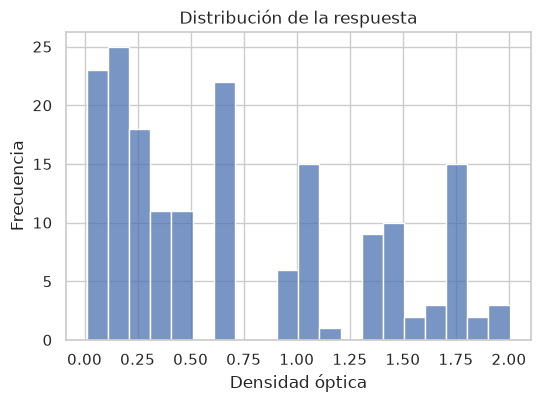

In [15]:
fig, eje = plt.subplots(figsize=(6, 4))
sns.histplot(data=datos, x=COLUMNA_Y, bins=20, ax=eje)
eje.set(title="Distribución de la respuesta", xlabel=NOMBRE_Y, ylabel="Frecuencia")
plt.show()

#### Consigna 3.1 · Tres gráficos, tres preguntas

Hacé los otros tres gráficos de la tabla:

- **Dispersión:** densidad óptica (eje y) contra concentración (eje x), con un color distinto para cada corrida.
- **Boxplot:** una caja por cada concentración patrón (8 cajas), con las 22 lecturas de esa concentración.
- **Barras:** una barra por corrida (11 barras), con su densidad óptica media en la concentración más alta (12,5).

**Se espera:** tres gráficos con título y con ejes legibles ("Concentración de DNasa", "Densidad óptica", "Corrida"), no con los nombres de las columnas (`conc`, `density`, `Run`).

**Antes de seguir:** ¿qué gráfico muestra mejor que algunas corridas leen más alto que otras? ¿Cuáles son?

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

Pedí los gráficos de a uno. Para las barras, primero quedate solo con las filas de concentración 12,5.

</details>

> **Prompt de referencia (docente)**
>
> Hacé una figura con tres paneles usando seaborn: dispersión de `COLUMNA_Y` contra `COLUMNA_X` coloreada por `COLUMNA_GRUPO`, boxplot de `COLUMNA_Y` para cada valor de `COLUMNA_X`, y barras con la media de `COLUMNA_Y` por `COLUMNA_GRUPO` en el valor más alto de `COLUMNA_X`. Usá `NOMBRE_X`, `NOMBRE_Y` y `NOMBRE_GRUPO` en los ejes.

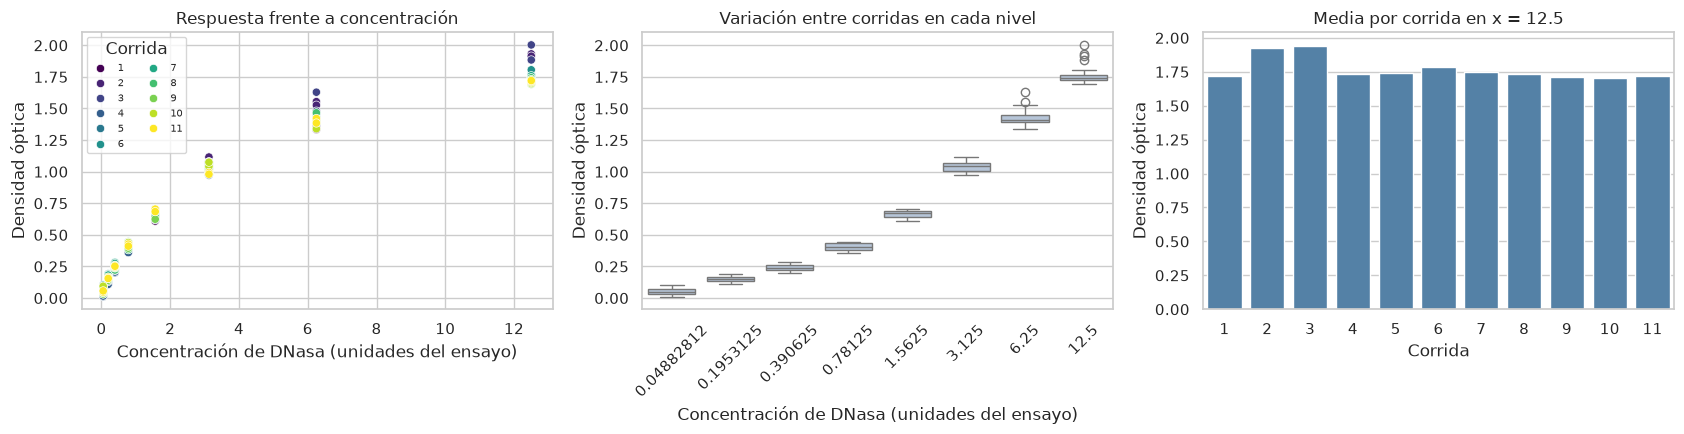

In [16]:
fig, ejes = plt.subplots(1, 3, figsize=(17, 4.5))

sns.scatterplot(data=datos, x=COLUMNA_X, y=COLUMNA_Y, hue=COLUMNA_GRUPO, palette="viridis", legend="full", ax=ejes[0])
ejes[0].set(title="Respuesta frente a concentración", xlabel=NOMBRE_X, ylabel=NOMBRE_Y)
ejes[0].legend(title=NOMBRE_GRUPO, fontsize=7, ncol=2)

sns.boxplot(data=datos, x=COLUMNA_X, y=COLUMNA_Y, ax=ejes[1], color="lightsteelblue")
ejes[1].set(title="Variación entre corridas en cada nivel", xlabel=NOMBRE_X, ylabel=NOMBRE_Y)
ejes[1].tick_params(axis="x", rotation=45)

nivel_mas_alto = datos[datos[COLUMNA_X] == datos[COLUMNA_X].max()]
sns.barplot(data=nivel_mas_alto, x=COLUMNA_GRUPO, y=COLUMNA_Y, ax=ejes[2], color="steelblue", errorbar=None)
ejes[2].set(title=f"Media por corrida en x = {datos[COLUMNA_X].max()}", xlabel=NOMBRE_GRUPO, ylabel=NOMBRE_Y)

plt.tight_layout()
plt.show()

#### Consigna 3.2 · Una figura para publicar

Hacé un gráfico de la densidad óptica media en cada concentración patrón (el promedio de sus 22 lecturas), con barras de error de un desvío estándar y las lecturas individuales de fondo.

Después elegí una revista de tu área y pedile al asistente que adapte la figura a sus normas para autores: tamaño (una o dos columnas), tipografía y tamaño de letra, grosor de líneas, resolución y formato del archivo. Guardá la figura en un archivo.

**Se espera:** la figura guardada en un archivo y una tabla corta con tres requisitos de la revista: qué dice la guía para autores, qué hizo el asistente y si coincide.

**Antes de seguir:** el asistente puede afirmar con seguridad normas que no son las reales. ¿Cuántos de los tres requisitos coincidieron con la guía oficial?

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

Buscá la guía para autores en la página de la revista (suele llamarse *Author Guidelines* o *Guide for Authors*) y buscá la sección de figuras o *artwork*. Las concentraciones siguen una dilución seriada: ¿qué escala del eje x las separa mejor?

</details>

> **Prompt de referencia (docente)**
>
> Hacé un gráfico de la media de `COLUMNA_Y` en cada valor de `COLUMNA_X`, con barras de error de un desvío estándar, eje x en escala logarítmica, puntos individuales semitransparentes de fondo, título descriptivo, letras grandes y estilo limpio para una presentación.

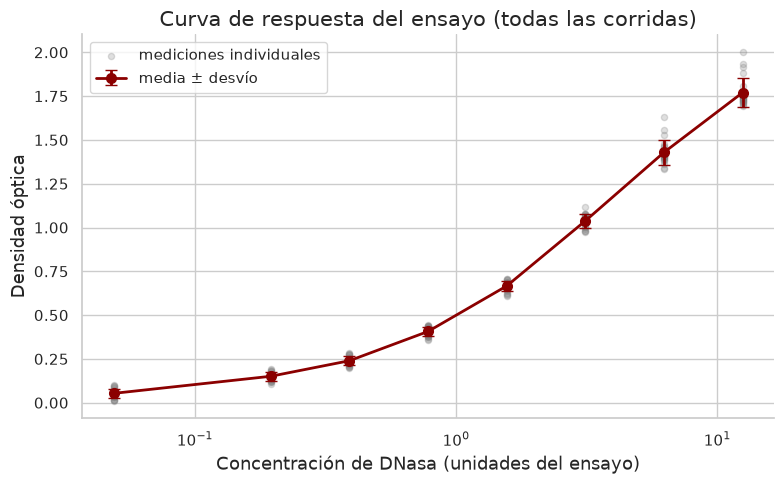

In [17]:
medias = datos.groupby(COLUMNA_X)[COLUMNA_Y].agg(["mean", "std"]).reset_index()

fig, eje = plt.subplots(figsize=(8, 5))
eje.scatter(datos[COLUMNA_X], datos[COLUMNA_Y], color="gray", alpha=0.25, s=20, label="mediciones individuales")
eje.errorbar(medias[COLUMNA_X], medias["mean"], yerr=medias["std"], fmt="o-", color="darkred",
             capsize=4, linewidth=2, markersize=7, label="media ± desvío")
eje.set_xscale("log")
eje.set_xlabel(NOMBRE_X, fontsize=13)
eje.set_ylabel(NOMBRE_Y, fontsize=13)
eje.set_title("Curva de respuesta del ensayo (todas las corridas)", fontsize=15)
eje.legend(fontsize=11)
sns.despine()
plt.tight_layout()
plt.show()

> **Prompt de referencia (docente)**
>
> Adaptá la figura anterior a las normas de figuras de ACS para *Analytical Chemistry*: una columna (3,33 pulgadas de ancho como máximo), tipografía Arial o Helvetica, letra de al menos 4,5 pt, líneas de al menos 0,5 pt, sin depender solo del color y sin título dentro de la figura. Guardala como TIFF a 300 dpi. Después informá el ancho real del archivo, su resolución y la tipografía que se usó.

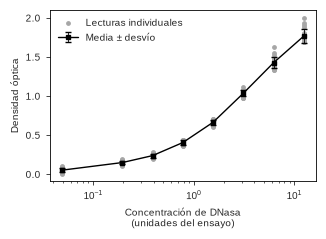

Archivo: figura_calibracion_acs.tif
Tamaño: 999 x 720 píxeles -> 3.33 x 2.40 pulgadas
Resolución guardada: (300.0, 300.0)
Tipografía usada: Liberation Sans, 7 pt


In [18]:
# Normas de figuras de ACS, guía para autores de Analytical Chemistry (consultada el 21/10/2026):
# una columna de hasta 3,33 in de ancho; letra de al menos 4,5 pt (Helvetica o Arial);
# líneas de al menos 0,5 pt; figuras en color a 300 dpi como mínimo; no depender solo del color.
from PIL import Image

ANCHO_UNA_COLUMNA = 3.33   # pulgadas
RESOLUCION = 300           # dpi
ARCHIVO_FIGURA = "figura_calibracion_acs.tif"

estilo_acs = {
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"],  # la primera disponible
    # El tema de seaborn fija por separado el tamaño de cada texto: hay que fijarlos todos
    "font.size": 7,
    "axes.labelsize": 7,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.grid": False,   # sin grilla de fondo, como en una figura publicada
    "axes.linewidth": 0.6,
    "axes.edgecolor": "black",
    "xtick.bottom": True,  # marcas de graduación en los ejes
    "ytick.left": True,
    "xtick.major.size": 3,
    "ytick.major.size": 3,
    "xtick.minor.size": 1.5,
    "xtick.minor.width": 0.5,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
}

# rc_context aplica el estilo solo a esta figura, sin cambiar los gráficos que siguen
with plt.rc_context(estilo_acs):
    fig, eje = plt.subplots(figsize=(ANCHO_UNA_COLUMNA, 2.4))
    eje.scatter(datos[COLUMNA_X], datos[COLUMNA_Y], s=6, marker="o", color="0.65", label="Lecturas individuales")
    eje.errorbar(medias[COLUMNA_X], medias["mean"], yerr=medias["std"], fmt="s-", color="black",
                 markersize=3, linewidth=1, elinewidth=0.6, capsize=2, label="Media ± desvío")
    eje.set_xscale("log")
    eje.set_xlabel("Concentración de DNasa\n(unidades del ensayo)")  # en dos líneas para que entre en una columna
    eje.set_ylabel(NOMBRE_Y)
    eje.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(ARCHIVO_FIGURA, dpi=RESOLUCION)
    fuente_usada = eje.xaxis.label.get_fontname()  # la tipografía que se usó de verdad
    tamano_letra = eje.xaxis.label.get_size()
    plt.show()

# Verificación: qué quedó realmente en el archivo
with Image.open(ARCHIVO_FIGURA) as imagen:
    ancho_px, alto_px = imagen.size
    dpi_archivo = imagen.info.get("dpi")
print(f"Archivo: {ARCHIVO_FIGURA}")
print(f"Tamaño: {ancho_px} x {alto_px} píxeles -> {ancho_px / RESOLUCION:.2f} x {alto_px / RESOLUCION:.2f} pulgadas")
print(f"Resolución guardada: {dpi_archivo}")
print(f"Tipografía usada: {fuente_usada}, {tamano_letra:.0f} pt")


**Tabla de verificación de referencia (docente).** Requisitos tomados de la [guía para autores de *Analytical Chemistry*](https://researcher-resources.acs.org/publish/author_guidelines?coden=ancham), consultada el 21/10/2026, contra lo que imprimió la celda anterior.

| Requisito | Qué dice la guía de ACS | Qué tiene la figura | ¿Coincide? |
|---|---|---|---|
| Ancho de una columna | hasta 240 pt (3,33 in) | 999 píxeles a 300 dpi = 3,33 in | Sí |
| Resolución (figura en color) | al menos 300 dpi | 300 dpi | Sí |
| Tipografía | Helvetica o Arial, letra de al menos 4,5 pt | 7 pt, medido sobre la figura, pero en Liberation Sans: Arial no estaba instalada y matplotlib usó la siguiente de la lista | **No del todo**: Liberation Sans tiene las mismas medidas que Arial, pero no es la misma fuente |

La tipografía es un buen ejemplo para la discusión: el código *pide* Arial, pero si la fuente no está instalada se usa otra sin aviso visible. Solo se descubre verificando. La fuente disponible puede cambiar de una computadora a otra.

Dos trampas que aparecieron al preparar este ejemplo, útiles para la discusión:

- **La pantalla no es el archivo.** En el cuaderno la figura se veía bien, pero en el TIFF guardado el rótulo del eje x quedaba cortado: la vista previa recorta los márgenes automáticamente y el archivo no. Hay que revisar el archivo que se entrega.
- **Un estilo puede pisar otro.** El tema de seaborn configurado al inicio fijaba por su cuenta el tamaño de cada texto, y la letra salía de unos 10 pt aunque el código pidiera 7. Solo se detectó midiendo sobre la figura.

#### Consigna 3.3 · Verificación: el gráfico contra la tabla

Elegí una concentración patrón en el boxplot y leé a ojo la mediana de su caja (la línea del medio). Comparala con el valor que imprime la celda siguiente.

**Se espera:** que tu lectura y el valor de la tabla difieran en menos de 0,05.

In [19]:
print(datos.groupby(COLUMNA_X)[COLUMNA_Y].median().round(3).to_string())

conc
0.048828     0.051
0.195312     0.154
0.390625     0.240
0.781250     0.406
1.562500     0.674
3.125000     1.042
6.250000     1.409
12.500000    1.739


## Bloque 4 · Regresión, sobreajuste y métricas (60 min)

**Producto:** ajuste lineal, ajuste de curvas y gráfico de error por grado del polinomio.

Retomamos la pregunta de la teoría: **¿un modelo que se ajusta mejor a los datos que ya tenemos es un modelo mejor?**

### 4.1 Regresión lineal simple: curva de calibración (15 min)

Usamos una sola corrida y solo el tramo bajo de concentraciones, donde la respuesta es aproximadamente lineal.

> **Una simplificación.** La ley de Beer-Lambert vale para el producto coloreado dentro del pocillo: su absorbancia es proporcional a su concentración. Pero en un ELISA la relación entre la concentración del **analito** y la densidad óptica no es lineal, porque los sitios de unión del anticuerpo se saturan. Solo es aproximadamente lineal en el tramo bajo. En el laboratorio, la calibración de un ELISA se ajusta con una logística de cuatro parámetros (la vemos en el paso 4.2); aquí usamos el tramo lineal para aprender a leer pendiente, ordenada y R².

**Ejemplo resuelto.** Selección de los datos de calibración: una corrida y el tramo lineal.

In [20]:
calibracion = datos[(datos[COLUMNA_GRUPO] == GRUPO_CALIBRACION) & (datos[COLUMNA_X] <= X_MAX_LINEAL)]
x_cal = calibracion[[COLUMNA_X]].to_numpy()
y_cal = calibracion[COLUMNA_Y].to_numpy()
print(f"Puntos de calibración: {len(calibracion)}")

Puntos de calibración: 10


#### Consigna 4.1 · La recta de calibración

Ajustá una regresión lineal de `y_cal` contra `x_cal` y graficá los puntos con la recta.

**Se espera:** la pendiente, la ordenada al origen y el R² impresos con cuatro decimales, cada uno con sus unidades, y un gráfico con la ecuación de la recta en la leyenda.

**Antes de seguir:** ¿En qué unidades está la pendiente? ¿Qué significa, físicamente, la ordenada al origen?

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

scikit-learn tiene un modelo de regresión lineal. La pendiente y la ordenada quedan guardadas dentro del modelo después de ajustarlo.

</details>

> **Prompt de referencia (docente)**
>
> Ajustá una regresión lineal de `y_cal` contra `x_cal`. Guardá la pendiente en `pendiente` y la ordenada en `ordenada`, informá ambas con el R², y graficá los puntos con la recta y su ecuación en la leyenda.

Pendiente: 0.3802 (unidades de y por unidad de x)
Ordenada:  0.0410 (unidades de y)
R²:        0.9804


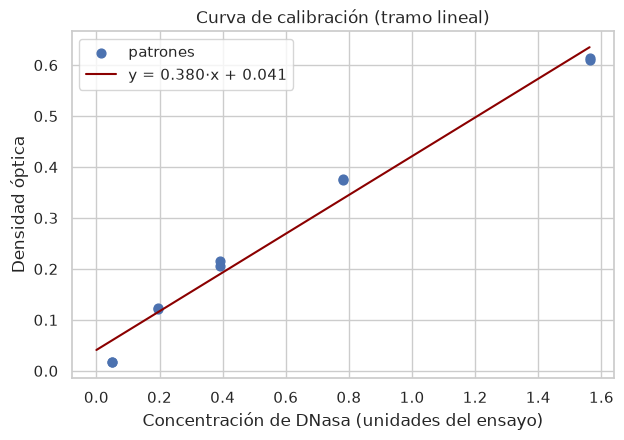

In [21]:
modelo_lineal = LinearRegression().fit(x_cal, y_cal)
pendiente = modelo_lineal.coef_[0]
ordenada = modelo_lineal.intercept_
r2_cal = r2_score(y_cal, modelo_lineal.predict(x_cal))

print(f"Pendiente: {pendiente:.4f} (unidades de y por unidad de x)")
print(f"Ordenada:  {ordenada:.4f} (unidades de y)")
print(f"R²:        {r2_cal:.4f}")

x_linea = np.linspace(0, x_cal.max(), 100).reshape(-1, 1)
fig, eje = plt.subplots(figsize=(7, 4.5))
eje.scatter(x_cal, y_cal, s=40, label="patrones")
eje.plot(x_linea, modelo_lineal.predict(x_linea), color="darkred", label=f"y = {pendiente:.3f}·x + {ordenada:.3f}")
eje.set(xlabel=NOMBRE_X, ylabel=NOMBRE_Y, title="Curva de calibración (tramo lineal)")
eje.legend()
plt.show()

#### Consigna 4.2 · ¿Cómo predecir? La concentración de una muestra desconocida

Una curva de calibración se ajusta en un sentido y se usa en el otro: se ajusta la densidad óptica en función de la concentración, pero en el laboratorio se mide la densidad óptica de una muestra y se quiere saber su concentración.

Una muestra de concentración desconocida dio una densidad óptica de **0,30** (`DENSIDAD_MUESTRA`). Despejá x de la recta y calculá **a mano** su concentración. Después pedí que se calcule con código y que se marque la muestra en el gráfico de la calibración.

**Se espera:** la concentración calculada a mano y con código, que tienen que coincidir, y el gráfico con la muestra marcada sobre la recta.

**Antes de seguir:** ¿qué harías si la muestra hubiera dado una densidad óptica de 1,5? ¿Se puede usar esta recta?

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

Si y = pendiente · x + ordenada, ¿cuánto vale x?

</details>

> **Prompt de referencia (docente)**
>
> Con `pendiente` y `ordenada`, calculá la concentración que corresponde a una densidad óptica de `DENSIDAD_MUESTRA` despejando x de la recta. Comprobá el resultado evaluando el modelo en esa concentración y graficá los patrones, la recta y la muestra marcada con líneas punteadas hasta los ejes.

A mano: (0.3 - 0.0410) / 0.3802 = 0.681
Comprobación: la recta en x = 0.681 da y = 0.300


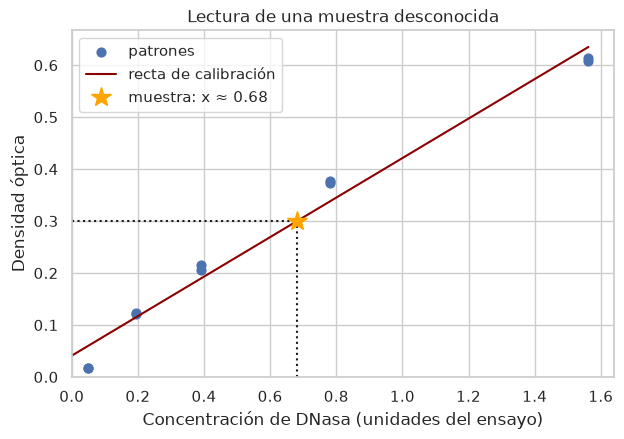

In [22]:
# Predicción inversa: de y = pendiente · x + ordenada se despeja x = (y - ordenada) / pendiente
concentracion_muestra = (DENSIDAD_MUESTRA - ordenada) / pendiente
print(f"A mano: ({DENSIDAD_MUESTRA} - {ordenada:.4f}) / {pendiente:.4f} = {concentracion_muestra:.3f}")

# Comprobación: la recta evaluada en esa concentración tiene que devolver la densidad medida
print(f"Comprobación: la recta en x = {concentracion_muestra:.3f} da y = {modelo_lineal.predict([[concentracion_muestra]])[0]:.3f}")

fig, eje = plt.subplots(figsize=(7, 4.5))
eje.scatter(x_cal, y_cal, s=40, label="patrones")
eje.plot(x_linea, modelo_lineal.predict(x_linea), color="darkred", label="recta de calibración")
eje.plot([0, concentracion_muestra], [DENSIDAD_MUESTRA, DENSIDAD_MUESTRA], "k:")
eje.plot([concentracion_muestra, concentracion_muestra], [0, DENSIDAD_MUESTRA], "k:")
eje.plot(concentracion_muestra, DENSIDAD_MUESTRA, "*", color="orange", markersize=15,
         label=f"muestra: x ≈ {concentracion_muestra:.2f}")
eje.set(xlabel=NOMBRE_X, ylabel=NOMBRE_Y, title="Lectura de una muestra desconocida", xlim=(0, None), ylim=(0, None))
eje.legend()
plt.show()


#### Interpretación

- **Pendiente ≈ 0,380** unidades de densidad óptica por unidad de concentración: es la **sensibilidad** del ensayo en este tramo. Cuanto mayor, más cambia la lectura por cada unidad de analito.
- **Ordenada ≈ 0,041**: la respuesta esperada sin analito, es decir la señal de fondo o del blanco.
- **R² ≈ 0,980**: la recta explica el 98 % de la variación de la respuesta en el tramo hasta 1,56 unidades. Un R² alto no prueba que la relación sea lineal; conviene mirar el gráfico.
- En el gráfico de la muestra se ve que los patrones no se reparten al azar alrededor de la recta: los de los extremos quedan por debajo y los del medio por encima. Es una curvatura leve que el R² de 0,98 no muestra, y anticipa por qué en el paso 4.2 se usa una curva.
- **Muestra desconocida:** una densidad óptica de 0,30 corresponde a ≈ 0,68 unidades de concentración.
- Una muestra con densidad óptica 1,5 queda fuera del tramo lineal (la recta llega a ≈ 0,63 en el patrón de 1,56). Extrapolar la recta daría un valor sin respaldo: en el laboratorio se diluiría la muestra para que caiga en el tramo calibrado, o se usaría la curva completa del paso 4.2.

### 4.2 Ajuste de curvas (15 min)

Ahora usamos el **rango completo** de concentraciones de la misma corrida. La respuesta se curva y se satura. Vamos a comparar tres tipos de modelo:

1. una recta;
2. polinomios de grado 2 y 3;
3. una función con sentido físico: la **logística de cuatro parámetros**, el modelo estándar de los inmunoensayos. Describe una respuesta que parte de un mínimo, crece y se satura cuando se ocupan todos los sitios de unión.

$$y = A + \frac{B - A}{1 + e^{(x_{medio} - \ln x)/escala}}$$

**¿Por qué una S?** Los anticuerpos del pocillo tienen una cantidad limitada de sitios de unión. Con muy poco analito, la señal apenas se separa del fondo; en la zona media, cada aumento de concentración ocupa más sitios y la señal crece rápido; con mucho analito, los sitios están casi todos ocupados y la señal se satura. Graficada contra el **logaritmo** de la concentración, esa respuesta tiene forma de S.

**Qué representa cada parámetro en el experimento:**

| Parámetro | En la curva | En el ensayo |
|---|---|---|
| **A** | asíntota inferior | señal sin analito: el fondo o blanco |
| **B** | asíntota superior | señal con todos los sitios ocupados: la saturación |
| **x_medio** | punto de inflexión, en ln(x) | ln de la concentración que da la mitad de la respuesta entre A y B. Su exponencial es la **EC50**, una medida de la sensibilidad del ensayo |
| **escala** | qué tan empinada es la S | cuanto más chica, más abrupto el paso del fondo a la saturación y más angosto el rango útil de medición |

La zona útil para medir muestras es la parte central de la S: allí un cambio de concentración produce un cambio claro de señal. Cerca de las mesetas, la señal casi no cambia y la concentración queda mal determinada.

**Ejemplo resuelto.** Los datos de la corrida completa y dos funciones que vamos a usar: la logística y el RMSE.

In [23]:
corrida = datos[datos[COLUMNA_GRUPO] == GRUPO_CALIBRACION]
x_c = corrida[COLUMNA_X].to_numpy()
y_c = corrida[COLUMNA_Y].to_numpy()

def logistica_4p(x, A, B, x_medio, escala):
    """Logística de cuatro parámetros en función de ln(x)."""
    return A + (B - A) / (1 + np.exp((x_medio - np.log(x)) / escala))

def rmse(y_real, y_predicho):
    """Raíz del error cuadrático medio, en las unidades de y."""
    return np.sqrt(mean_squared_error(y_real, y_predicho))

**Ejemplo resuelto.** Una logística con valores **ilustrativos** (no ajustados a los datos) para ver qué controla cada parámetro. Pedile al asistente que cambie uno de los valores y observá cómo se mueve la curva.

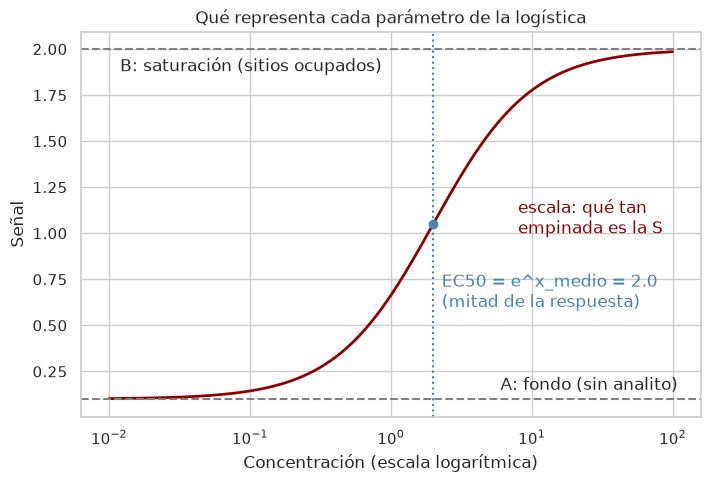

In [24]:
# Valores ilustrativos, elegidos para que se vea cada parámetro (no son un ajuste)
A, B, x_medio, escala = 0.1, 2.0, np.log(2.0), 0.8
ec50 = np.exp(x_medio)

x_ilustracion = np.geomspace(0.01, 100, 300)
fig, eje = plt.subplots(figsize=(8, 5))
eje.plot(x_ilustracion, logistica_4p(x_ilustracion, A, B, x_medio, escala), color="darkred", linewidth=2)
eje.axhline(A, color="gray", linestyle="--")
eje.axhline(B, color="gray", linestyle="--")
eje.axvline(ec50, color="steelblue", linestyle=":")
eje.plot(ec50, (A + B) / 2, "o", color="steelblue")

eje.text(6, A + 0.05, "A: fondo (sin analito)")
eje.text(0.012, B - 0.12, "B: saturación (sitios ocupados)")
eje.text(ec50 * 1.15, 0.6, f"EC50 = e^x_medio = {ec50:.1f}\n(mitad de la respuesta)", color="steelblue")
eje.text(8, 1.0, "escala: qué tan\nempinada es la S", color="darkred")

eje.set_xscale("log")
eje.set(xlabel="Concentración (escala logarítmica)", ylabel="Señal", title="Qué representa cada parámetro de la logística")
plt.show()


#### Consigna 4.3 · Cuatro modelos para la misma curva

Ajustá a `x_c` e `y_c` una recta, un polinomio de grado 2, uno de grado 3 y la función `logistica_4p`. Compará los cuatro.

**Se espera:** una tabla con el RMSE de cada modelo y un gráfico con las mediciones y las cuatro curvas. Imprimí los cuatro parámetros ajustados de la logística.

**Antes de seguir:** ¿El modelo con menor RMSE es necesariamente el mejor? Mirá la forma de cada curva entre los puntos.

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

Los polinomios se ajustan con numpy. Para la logística hace falta `curve_fit` de scipy, que necesita valores iniciales razonables: A cerca de la respuesta mínima, B cerca de la máxima, x_medio cerca del logaritmo de una concentración intermedia y escala cerca de 1.

</details>

> **Prompt de referencia (docente)**
>
> Con `x_c` e `y_c`, ajustá una recta, un polinomio de grado 2, uno de grado 3 y `logistica_4p` (con `curve_fit`, guardando los parámetros en `parametros_4p`). Mostrá una tabla con el RMSE de cada modelo, graficá los datos con las cuatro curvas e imprimí los parámetros de la logística.

,RMSE
recta,0.2059
polinomio grado 2,0.0693
polinomio grado 3,0.0165
logística 4 parámetros,0.0172


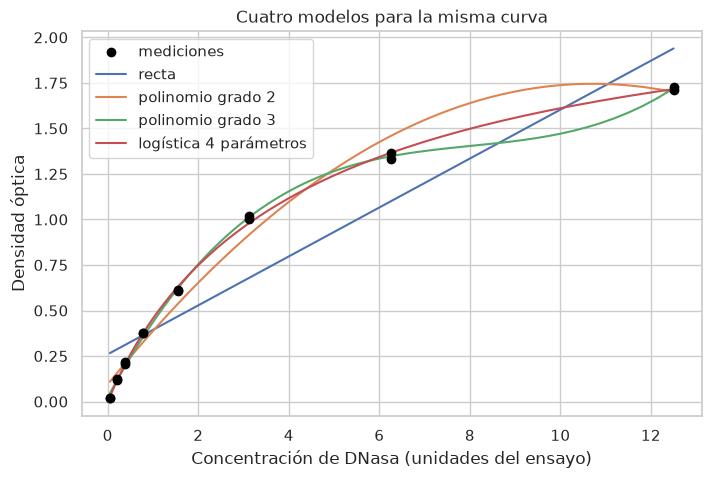

Parámetros de la logística (A, B, x_medio, escala): [-0.008  2.377  1.507  1.063]


In [25]:
# Ajuste de cada modelo
predicciones = {}
for grado in [1, 2, 3]:
    coeficientes = np.polyfit(x_c, y_c, grado)
    nombre = "recta" if grado == 1 else f"polinomio grado {grado}"
    predicciones[nombre] = lambda x, c=coeficientes: np.polyval(c, x)

parametros_4p, _ = curve_fit(logistica_4p, x_c, y_c, p0=[0, y_c.max(), np.log(np.median(x_c)), 1])
predicciones["logística 4 parámetros"] = lambda x: logistica_4p(x, *parametros_4p)

tabla_ajustes = pd.DataFrame({"RMSE": {n: rmse(y_c, f(x_c)) for n, f in predicciones.items()}})
display(tabla_ajustes.round(4))

x_fino = np.geomspace(x_c.min(), x_c.max(), 200)
fig, eje = plt.subplots(figsize=(8, 5))
eje.scatter(x_c, y_c, color="black", zorder=3, label="mediciones")
for nombre, f in predicciones.items():
    eje.plot(x_fino, f(x_fino), label=nombre)
eje.set(xlabel=NOMBRE_X, ylabel=NOMBRE_Y, title="Cuatro modelos para la misma curva")
eje.legend()
plt.show()
print("Parámetros de la logística (A, B, x_medio, escala):", np.round(parametros_4p, 3))

#### Consigna 4.4 · Verificación: ¿los parámetros tienen sentido?

Los parámetros de la logística tienen significado: **A** es la respuesta sin analito (el blanco) y **B** es la meseta a concentración muy alta. Compará A con la respuesta medida en la concentración más baja, y B con la respuesta más alta medida.

**Se espera:** que A se parezca a la lectura del patrón más bajo y que B sea mayor que la lectura más alta. Mirando el gráfico, decidí si la curva llegó a la meseta dentro del rango medido.

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

Los parámetros quedaron guardados en el orden A, B, x_medio, escala.

</details>

In [26]:
print(f"A ajustado = {parametros_4p[0]:.3f}   |   respuesta media en la x más baja = {y_c[x_c == x_c.min()].mean():.3f}")
print(f"B ajustado = {parametros_4p[1]:.3f}   |   respuesta más alta medida = {y_c.max():.3f}")

A ajustado = -0.008   |   respuesta media en la x más baja = 0.018
B ajustado = 2.377   |   respuesta más alta medida = 1.730


#### Interpretación

- La recta es claramente insuficiente (RMSE ≈ 0,206).
- El polinomio de grado 3 y la logística tienen un RMSE casi igual (≈ 0,017), pero entre 6 y 12 unidades el polinomio forma un escalón que no tiene sentido físico y no sirve para extrapolar.
- La logística tiene parámetros interpretables: A ≈ −0,008, cercano a la lectura del patrón más bajo (≈ 0,018), y B ≈ 2,38, una meseta que la curva todavía no alcanza en el rango medido (máximo ≈ 1,73).
- Moraleja: **un RMSE parecido no hace equivalentes a dos modelos**; también importa si la forma tiene sentido.

### 4.3 Sobreajuste (20 min)

> ⚠️ **Datos simulados.** Las mediciones reales de cada corrida tienen solo 8 concentraciones distintas, medidas por duplicado. Con tan pocos valores distintos de x no se puede mostrar bien el sobreajuste. Por eso **simulamos** un conjunto de 18 puntos:
>
> - la curva "verdadera" es la logística de cuatro parámetros ajustada a **todas** las corridas reales;
> - el ruido es gaussiano, con el desvío de los residuos de ese mismo ajuste (es decir, la variabilidad real entre corridas).
>
> Así, la forma y el ruido salen de los datos, pero los puntos no son mediciones.
>
> **Otra simplificación:** el ruido simulado es igual en toda la curva. En los datos reales, el desvío entre corridas crece con la concentración: es de 0,024 a 0,031 en los cinco patrones más bajos y sube a 0,069 y 0,085 en los dos más altos. Por eso, en la práctica, los ajustes de ELISA suelen dar menos peso a los puntos más ruidosos (regresión ponderada). Aquí no lo hacemos, para concentrarnos en el sobreajuste.

**Ejemplo resuelto.** Generación del conjunto simulado. Ejecutala y leé los comentarios.

In [27]:
# Curva verdadera y ruido, estimados con todas las corridas reales
x_todas = datos[COLUMNA_X].to_numpy()
y_todas = datos[COLUMNA_Y].to_numpy()
parametros_verdaderos, _ = curve_fit(logistica_4p, x_todas, y_todas, p0=[0, y_todas.max(), np.log(np.median(x_todas)), 1])
residuos = y_todas - logistica_4p(x_todas, *parametros_verdaderos)
desvio_ruido = residuos.std(ddof=len(parametros_verdaderos))

# Conjunto simulado: concentraciones espaciadas en escala logarítmica, como en una dilución seriada
generador = np.random.default_rng(SEMILLA)
x_sim = np.geomspace(x_todas.min(), x_todas.max(), N_SIMULADOS)
y_sim = logistica_4p(x_sim, *parametros_verdaderos) + generador.normal(0, desvio_ruido, N_SIMULADOS)

print(f"Desvío del ruido (de los residuos reales): {desvio_ruido:.4f}")
print(f"Puntos simulados: {N_SIMULADOS}")

Desvío del ruido (de los residuos reales): 0.0461
Puntos simulados: 18


#### Consigna 4.5 · Error de entrenamiento y de prueba por grado

Dividí los datos simulados en entrenamiento (70 %) y prueba (30 %) usando `SEMILLA`. Para cada grado de polinomio entre 1 y `GRADO_MAXIMO`, ajustá el modelo con los datos de entrenamiento y calculá el RMSE en los dos conjuntos. Trabajá con **ln(x_sim)** como variable de entrada: las concentraciones siguen una dilución seriada y en escala lineal quedarían amontonadas cerca de cero.

**Se espera:** una tabla con el RMSE de entrenamiento y de prueba para cada grado, y un gráfico de ambos contra el grado, con el eje y en escala logarítmica y una línea horizontal en `desvio_ruido`.

**Antes de seguir:** ¿Qué le pasa al error de entrenamiento a medida que sube el grado? ¿Y al de prueba?

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

scikit-learn tiene una función para dividir datos en entrenamiento y prueba, y otra para generar las potencias de x. Con grados altos conviene estandarizar x antes de elevarla a potencias; se pueden encadenar los pasos en un *pipeline*.

</details>

> **Prompt de referencia (docente)**
>
> Dividí `ln(x_sim)` e `y_sim` en entrenamiento (70 %) y prueba (30 %) con `random_state=SEMILLA`, guardando `x_entr`, `x_prueba`, `y_entr`, `y_prueba`. Para cada grado de 1 a `GRADO_MAXIMO`, ajustá un pipeline con StandardScaler, PolynomialFeatures y LinearRegression, y calculá el RMSE en entrenamiento y en prueba. Guardá los resultados en `tabla_grados` (índice: grado) y graficá ambos RMSE contra el grado con eje y logarítmico y una línea horizontal en `desvio_ruido`.

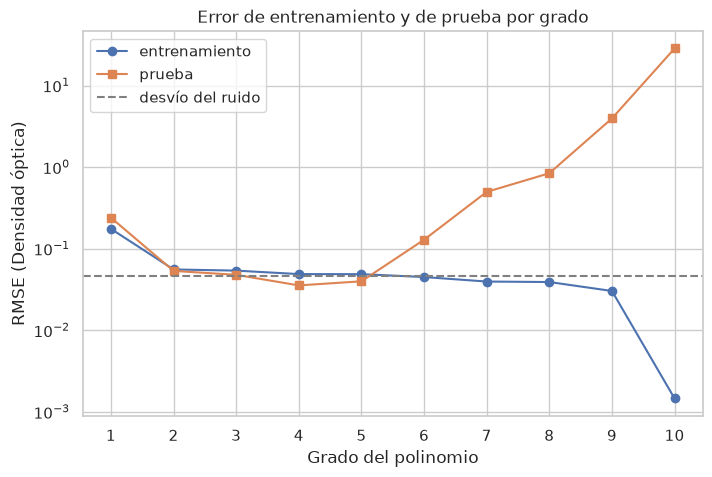

,RMSE entrenamiento,RMSE prueba
grado,,
1,0.1750,0.2399
2,0.0556,0.0534
3,0.0538,0.0478
4,0.0488,0.0355
5,0.0487,0.0398
6,0.0449,0.1286
7,0.0395,0.4964
8,0.0390,0.8405
9,0.0303,3.9469


In [28]:
x_entr, x_prueba, y_entr, y_prueba = train_test_split(
    np.log(x_sim).reshape(-1, 1), y_sim, test_size=0.3, random_state=SEMILLA)

grados = range(1, GRADO_MAXIMO + 1)
resultados = []
for grado in grados:
    # Se estandariza x antes de elevarlo a potencias altas, para evitar problemas numéricos
    modelo = make_pipeline(StandardScaler(), PolynomialFeatures(grado), LinearRegression())
    modelo.fit(x_entr, y_entr)
    resultados.append({
        "grado": grado,
        "RMSE entrenamiento": rmse(y_entr, modelo.predict(x_entr)),
        "RMSE prueba": rmse(y_prueba, modelo.predict(x_prueba)),
    })
tabla_grados = pd.DataFrame(resultados).set_index("grado")

fig, eje = plt.subplots(figsize=(8, 5))
eje.plot(tabla_grados.index, tabla_grados["RMSE entrenamiento"], "o-", label="entrenamiento")
eje.plot(tabla_grados.index, tabla_grados["RMSE prueba"], "s-", label="prueba")
eje.axhline(desvio_ruido, color="gray", linestyle="--", label="desvío del ruido")
eje.set_yscale("log")
eje.set(xlabel="Grado del polinomio", ylabel=f"RMSE ({NOMBRE_Y})", title="Error de entrenamiento y de prueba por grado")
eje.set_xticks(list(grados))
eje.legend()
plt.show()
tabla_grados.round(4)

#### Consigna 4.6 · Verificación: ¿dónde empieza el sobreajuste?

Mirando **solo el gráfico**, anotá el grado a partir del cual el error de prueba empeora. Después pedí que se calcule a partir de la tabla.

**Se espera:** tu lectura del gráfico y el grado con menor RMSE de prueba según la tabla. Si no coinciden, explicá por qué.

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

Buscá el grado donde la curva de prueba tiene su mínimo; pandas tiene una función que devuelve la posición del mínimo de una columna.

</details>

In [29]:
mejor_grado = tabla_grados["RMSE prueba"].idxmin()
print(f"Grado con menor RMSE de prueba: {mejor_grado}")
print(f"RMSE de prueba en ese grado: {tabla_grados.loc[mejor_grado, 'RMSE prueba']:.4f}")
print(f"RMSE de prueba en grado {GRADO_MAXIMO}: {tabla_grados.loc[GRADO_MAXIMO, 'RMSE prueba']:.4f}")

Grado con menor RMSE de prueba: 4
RMSE de prueba en ese grado: 0.0355
RMSE de prueba en grado 10: 28.4467


#### Consigna 4.7 · Ver el sobreajuste

Dibujá sobre los datos simulados dos polinomios ajustados con los datos de entrenamiento: el de mejor grado y el de `GRADO_MAXIMO`. Distinguí los puntos de entrenamiento de los de prueba.

**Se espera:** un gráfico con eje x en escala logarítmica donde se vea cómo el polinomio de grado alto pasa por los puntos de entrenamiento pero se aleja de los de prueba.

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

Los modelos se ajustaron con ln(x): para dibujarlos, generá muchos valores de ln(x) entre el mínimo y el máximo y volvé a la concentración con `np.exp`. Limitá el eje y para que las oscilaciones no aplasten el gráfico.

</details>

> **Prompt de referencia (docente)**
>
> Graficá los puntos de entrenamiento y de prueba (en concentración, con `np.exp`) y las curvas de los polinomios de grado `mejor_grado` y `GRADO_MAXIMO` ajustados con `x_entr` e `y_entr`. Eje x logarítmico y eje y limitado al rango de `y_sim` más 0,5 de margen.

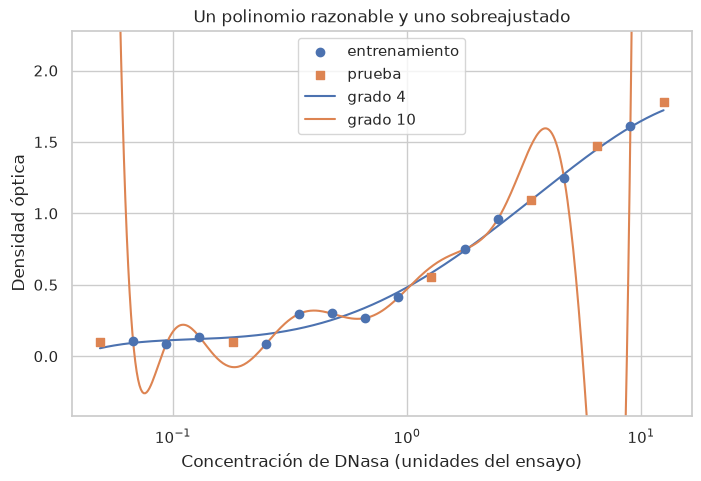

In [30]:
# Los modelos trabajan con ln(x); para dibujar se vuelve a la concentración con exp()
ln_x_dibujo = np.linspace(np.log(x_sim.min()), np.log(x_sim.max()), 400).reshape(-1, 1)
fig, eje = plt.subplots(figsize=(8, 5))
eje.scatter(np.exp(x_entr), y_entr, label="entrenamiento", zorder=3)
eje.scatter(np.exp(x_prueba), y_prueba, marker="s", label="prueba", zorder=3)
for grado in [mejor_grado, GRADO_MAXIMO]:
    modelo = make_pipeline(StandardScaler(), PolynomialFeatures(grado), LinearRegression()).fit(x_entr, y_entr)
    eje.plot(np.exp(ln_x_dibujo), modelo.predict(ln_x_dibujo), label=f"grado {grado}")
eje.set_xscale("log")
eje.set_ylim(y_sim.min() - 0.5, y_sim.max() + 0.5)
eje.set(xlabel=NOMBRE_X, ylabel=NOMBRE_Y, title="Un polinomio razonable y uno sobreajustado")
eje.legend()
plt.show()

**Para explorar:** cambiá `SEMILLA` en la configuración y volvé a ejecutar. ¿Cambia el grado óptimo? ¿Por qué podría cambiar con tan pocos puntos?

> **Nota docente.** Con esta configuración (18 puntos, ruido 0,046, ajuste sobre ln(x)), la forma en U clara aparece en unas 78 de cada 100 semillas, y el grado óptimo varía entre 2 y 5. La semilla 32 se eligió porque muestra un perfil limpio. Si un estudiante obtiene una curva irregular con otra semilla, es una buena oportunidad para hablar de la variabilidad con muestras pequeñas.

### 4.4 Métricas (10 min)

Tres preguntas:

1. ¿Por qué el R² sobre los datos de **entrenamiento** engaña?
2. ¿Qué significa el RMSE en las unidades de la variable medida?
3. ¿En qué se diferencian el RMSE y el MAE?

> **Nota docente: si falta tiempo.** Las consignas 4.8 (tabla de R², RMSE y MAE) y 4.9 (error en unidades de concentración) se pueden omitir. En ese caso, conviene igual discutir en voz alta las tres preguntas de esta sección, mostrando la tabla de métricas de este cuaderno resuelto. El dato más importante para comentar es que, en grado 10, el R² de entrenamiento es prácticamente 1 y el de prueba es muy negativo.

#### Consigna 4.8 · Tres métricas, dos conjuntos

Para el mejor grado y para `GRADO_MAXIMO`, calculá R², RMSE y MAE en entrenamiento y en prueba.

**Se espera:** una tabla con una fila por combinación de grado y conjunto, y una columna por métrica.

**Antes de seguir:** Compará el R² de entrenamiento y de prueba del grado máximo. ¿Qué significa un R² negativo?

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

Las tres métricas están en `sklearn.metrics`. Reajustá cada modelo con los datos de entrenamiento y evaluá con los dos conjuntos.

</details>

> **Prompt de referencia (docente)**
>
> Para `mejor_grado` y `GRADO_MAXIMO`, reajustá el polinomio con `x_entr` e `y_entr` y calculá R², RMSE y MAE en entrenamiento y en prueba. Guardá la tabla en `tabla_metricas` con índice (grado, conjunto).

In [31]:
filas = []
for grado in [mejor_grado, GRADO_MAXIMO]:
    modelo = make_pipeline(StandardScaler(), PolynomialFeatures(grado), LinearRegression()).fit(x_entr, y_entr)
    for conjunto, xx, yy in [("entrenamiento", x_entr, y_entr), ("prueba", x_prueba, y_prueba)]:
        pred = modelo.predict(xx)
        filas.append({"grado": grado, "conjunto": conjunto,
                      "R²": r2_score(yy, pred), "RMSE": rmse(yy, pred), "MAE": mean_absolute_error(yy, pred)})
tabla_metricas = pd.DataFrame(filas).set_index(["grado", "conjunto"])
tabla_metricas.round(4)

R²     RMSE      MAE
grado conjunto                                  
4     entrenamiento     0.9899   0.0488   0.0397
      prueba            0.9970   0.0355   0.0304
10    entrenamiento     1.0000   0.0015   0.0009
      prueba        -1932.0659  28.4467  14.6176

#### Consigna 4.9 · El error en unidades de concentración

Traducí el RMSE de prueba del mejor grado a unidades de concentración usando la pendiente de la calibración del paso 4.1.

**Se espera:** un valor en unidades de concentración y una frase que diga qué significa para quien mide una muestra.

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

En el tramo lineal, un error de respuesta de tamaño RMSE equivale aproximadamente a un error de concentración de RMSE / pendiente.

</details>

In [32]:
rmse_mejor = tabla_metricas.loc[(mejor_grado, "prueba"), "RMSE"]
print(f"RMSE de prueba (mejor grado): {rmse_mejor:.4f} unidades de {NOMBRE_Y.lower()}")
print(f"Equivale a ≈ {rmse_mejor / pendiente:.3f} unidades de concentración en el tramo lineal")

RMSE de prueba (mejor grado): 0.0355 unidades de densidad óptica
Equivale a ≈ 0.093 unidades de concentración en el tramo lineal


#### Interpretación

- En grado 10, el R² de entrenamiento es prácticamente 1, pero en prueba es negativo (≈ −1932): el modelo **memorizó** los puntos de entrenamiento y predice peor que usar el promedio. Por eso el R² de entrenamiento engaña.
- En grado 4, el RMSE de prueba (≈ 0,036) es del mismo orden que el desvío del ruido (≈ 0,046): ningún modelo puede bajar mucho de ese piso.
- En unidades de concentración, ese error equivale a ≈ 0,09 unidades en el tramo lineal.
- En grado 10, el MAE (≈ 14,6) es mucho menor que el RMSE (≈ 28,4): el RMSE castiga más a los pocos errores enormes de los bordes.
- Con solo 6 puntos de prueba, el azar pesa: en grado 4 el R² de prueba sale incluso mayor que el de entrenamiento.

## Cierre (10 min)

**Producto:** el cuaderno completo y guardado.

#### Consigna final · Elegir y justificar un modelo

1. Pedile al asistente que explique, en lenguaje sencillo, las tablas `tabla_ajustes`, `tabla_grados` y `tabla_metricas`, y que recomiende un modelo para describir la curva de respuesta.
2. **Verificá** la explicación contra las tablas: ¿cita bien los números? ¿Usa el error de prueba, y no el de entrenamiento, para elegir?
3. Escribí tu elección y justificala en tres o cuatro frases: qué métrica usaste, sobre qué datos y qué tiene de bueno o de malo el modelo.

**Tu elección y justificación:**

*...*